--- 1. LOADING & INSPECTING DATA ---
Dataset Shape (Rows, Columns): (123, 15)

Column Data Types:
 car_id              object
brand               object
model               object
year                object
price_inr          float64
km_driven           object
fuel_type           object
transmission        object
owner_type          object
mileage_kmpl       float64
engine_cc          float64
city                object
insurance_valid     object
seller_rating      float64
listed_date         object
dtype: object

Missing Values Count:
 car_id             0
brand              7
model              0
year               0
price_inr          5
km_driven          0
fuel_type          0
transmission       3
owner_type         0
mileage_kmpl       5
engine_cc          4
city               0
insurance_valid    0
seller_rating      0
listed_date        0
dtype: int64

Duplicate Rows Count: 3

First 5 Rows:
    car_id     brand   model  year  price_inr km_driven fuel_type transmission  \
0  CAR00

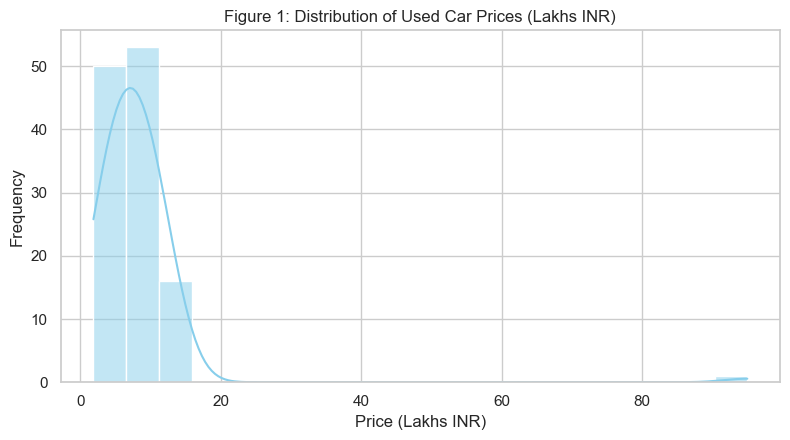

C:\Users\sp138\AppData\Local\Temp\ipykernel_5296\3020588376.py:97: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=brand_counts.index, y=brand_counts.values, palette='viridis')


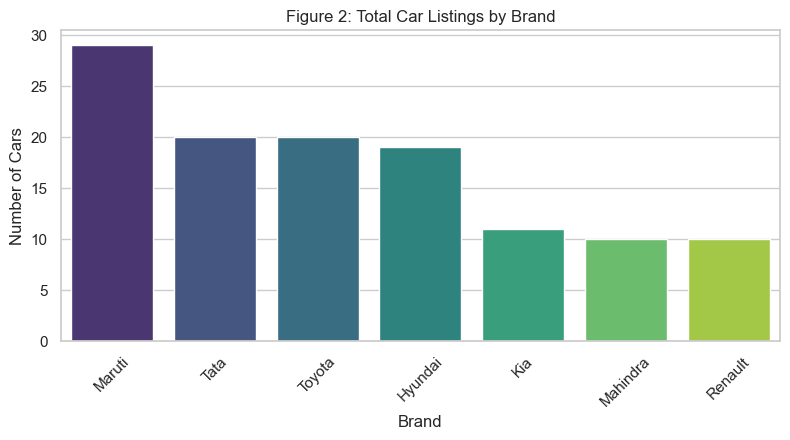

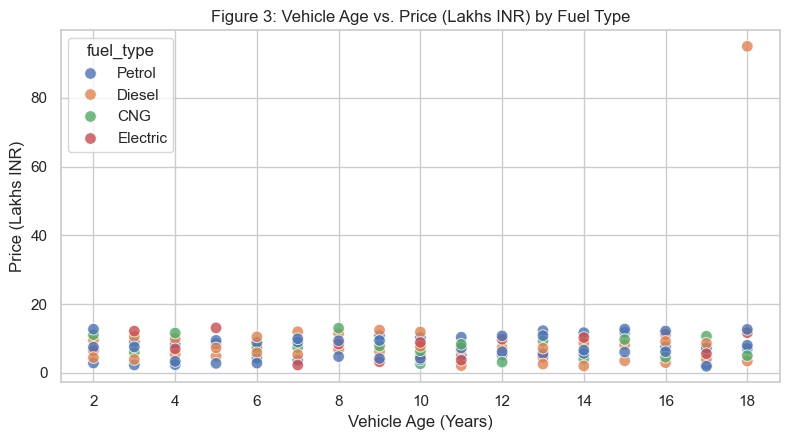

C:\Users\sp138\AppData\Local\Temp\ipykernel_5296\3020588376.py:114: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='transmission', y=df_clean['price_inr']/100000, palette='Set2')


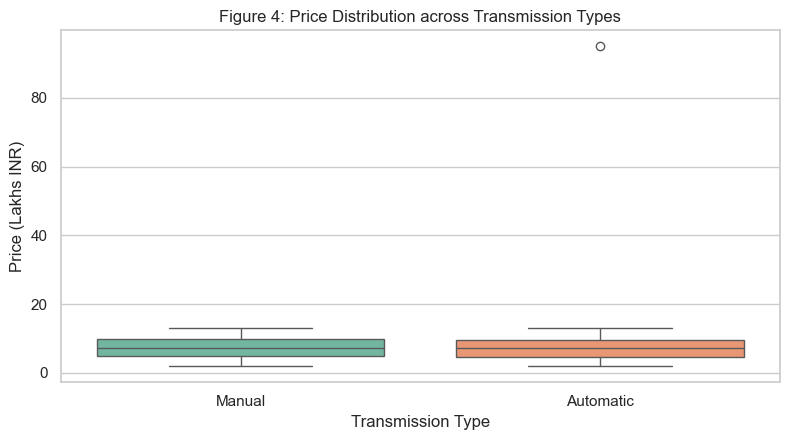

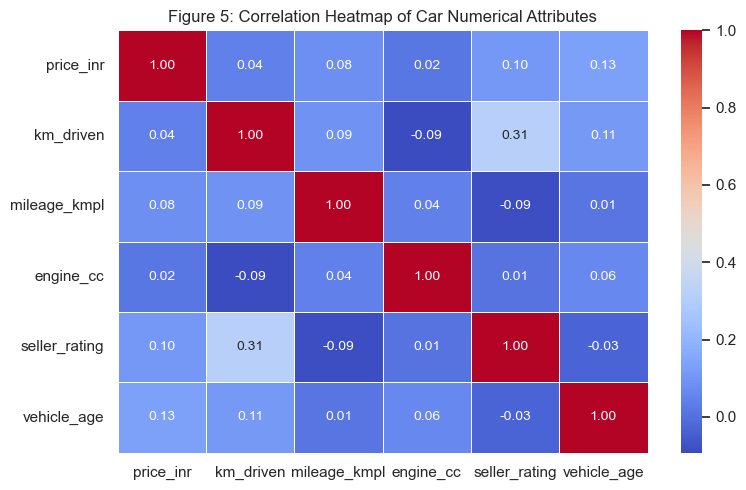

C:\Users\sp138\AppData\Local\Temp\ipykernel_5296\3020588376.py:129: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='fuel_type', y='mileage_kmpl', palette='Pastel1')


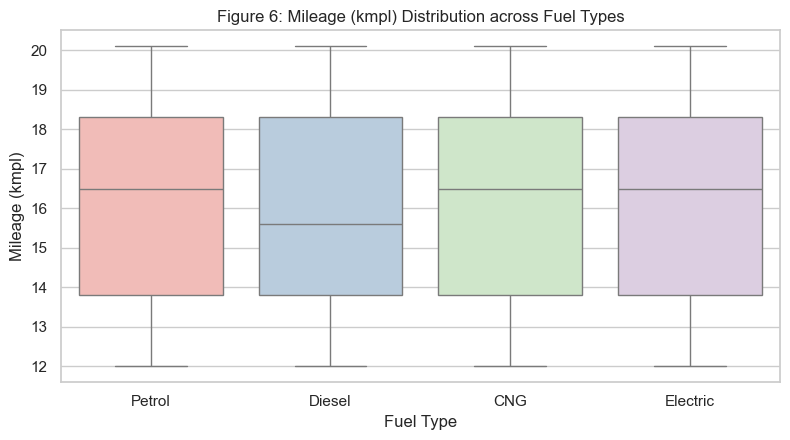


EDA Completed Successfully.


In [12]:
"""
===============================================================================
STUDENT PROJECT: Exploratory Data Analysis (EDA) on Used Cars Dataset
Dataset: uncleaned_used_cars_eda.csv
Name: Sakshi
Batch: A
Date: 28-09-2026
===============================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 10

print("--- 1. LOADING & INSPECTING DATA ---")
df = pd.read_csv(r'C:\Users\sp138\OneDrive\Desktop\unlox mini project\uncleaned_used_cars_eda.csv')

print(f"Dataset Shape (Rows, Columns): {df.shape}")
print("\nColumn Data Types:\n", df.dtypes)
print("\nMissing Values Count:\n", df.isnull().sum())
print(f"\nDuplicate Rows Count: {df.duplicated().sum()}")
print("\nFirst 5 Rows:\n", df.head())

print("\n--- 2. DATA CLEANING ---")
df_clean = df.copy()

df_clean = df_clean.drop_duplicates()

brand_mapping = {
    'maruti': 'Maruti', 'MARUTI': 'Maruti', 'Maruti': 'Maruti',
    'Hyundai': 'Hyundai', 'hyundai ': 'Hyundai', 'hyundai': 'Hyundai',
    'Tata': 'Tata', 'TATA': 'Tata',
    'Mahindra': 'Mahindra', 'Kia': 'Kia', 'Renault': 'Renault',
    'Toyota': 'Toyota', 'Toyta': 'Toyota'
}
df_clean['brand'] = df_clean['brand'].str.strip().map(lambda x: brand_mapping.get(x, x))

model_to_brand = {
    'Baleno': 'Maruti', 'i20': 'Hyundai', 'Creta': 'Hyundai', 
    'Nexon': 'Tata', 'XUV300': 'Mahindra', 'Seltos': 'Kia', 
    'Kwid': 'Renault', 'Innova': 'Toyota', 'Fortuner': 'Toyota', 'Swift': 'Maruti'
}
df_clean['brand'] = df_clean['brand'].fillna(df_clean['model'].map(model_to_brand))

df_clean['year'] = pd.to_numeric(df_clean['year'].replace('unknown', np.nan), errors='coerce')
df_clean['year'] = df_clean['year'].fillna(df_clean['year'].median()).astype(int)
df_clean['vehicle_age'] = 2026 - df_clean['year']

df_clean['km_driven'] = pd.to_numeric(
    df_clean['km_driven'].astype(str).str.replace(',', '').str.extract(r'(\d+)')[0], 
    errors='coerce'
)

df_clean['fuel_type'] = df_clean['fuel_type'].str.strip().str.capitalize().replace({'Cng': 'CNG'})

df_clean['transmission'] = df_clean['transmission'].str.strip().str.capitalize()
df_clean['transmission'] = df_clean['transmission'].replace({'Auto': 'Automatic'}).fillna('Manual')

owner_mapping = {'1st': 'First', 'First': 'First', '2nd': 'Second', 'Second': 'Second', '3rd': 'Third', 'Third': 'Third'}
df_clean['owner_type'] = df_clean['owner_type'].map(owner_mapping)

city_mapping = {
    'hyderabad': 'Hyderabad', 'Hyd': 'Hyderabad', 
    'Bangalore': 'Bengaluru', 'Bengaluru': 'Bengaluru', 
    'Mumbai': 'Mumbai', 'Pune': 'Pune', 'Chennai': 'Chennai', 
    'Delhi': 'Delhi', 'New Delhi': 'Delhi'
}
df_clean['city'] = df_clean['city'].map(city_mapping)
df_clean['insurance_valid'] = df_clean['insurance_valid'].str.strip().str.capitalize()

num_cols = ['price_inr', 'mileage_kmpl', 'engine_cc', 'km_driven']
for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print(f"Cleaned Dataset Shape: {df_clean.shape}")

print("\n--- 3. DESCRIPTIVE STATISTICS ---")
print("\nNumerical Statistics:\n", df_clean[['price_inr', 'km_driven', 'mileage_kmpl', 'engine_cc', 'seller_rating', 'vehicle_age']].describe())
print("\nCategorical Counts:\n", df_clean[['brand', 'fuel_type', 'transmission', 'owner_type', 'city']].nunique())

print("\n--- 4. GENERATING VISUALISATIONS ---")

plt.figure(figsize=(8, 4.5))
sns.histplot(df_clean['price_inr'] / 100000, kde=True, color='skyblue', bins=20)
plt.title('Figure 1: Distribution of Used Car Prices (Lakhs INR)')
plt.xlabel('Price (Lakhs INR)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
brand_counts = df_clean['brand'].value_counts()
sns.barplot(x=brand_counts.index, y=brand_counts.values, palette='viridis')
plt.title('Figure 2: Total Car Listings by Brand')
plt.xlabel('Brand')
plt.ylabel('Number of Cars')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
sns.scatterplot(data=df_clean, x='vehicle_age', y=df_clean['price_inr']/100000, hue='fuel_type', alpha=0.8, s=70)
plt.title('Figure 3: Vehicle Age vs. Price (Lakhs INR) by Fuel Type')
plt.xlabel('Vehicle Age (Years)')
plt.ylabel('Price (Lakhs INR)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df_clean, x='transmission', y=df_clean['price_inr']/100000, palette='Set2')
plt.title('Figure 4: Price Distribution across Transmission Types')
plt.xlabel('Transmission Type')
plt.ylabel('Price (Lakhs INR)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
corr = df_clean[['price_inr', 'km_driven', 'mileage_kmpl', 'engine_cc', 'seller_rating', 'vehicle_age']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Figure 5: Correlation Heatmap of Car Numerical Attributes')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df_clean, x='fuel_type', y='mileage_kmpl', palette='Pastel1')
plt.title('Figure 6: Mileage (kmpl) Distribution across Fuel Types')
plt.xlabel('Fuel Type')
plt.ylabel('Mileage (kmpl)')
plt.tight_layout()
plt.show()

print("\nEDA Completed Successfully.")